# Week 8 Jupyter Notebook – K-Nearest Neighbors
## Predicting Loan Default with Distance-Based Models

### Project Overview

For Week 8, I am continuing to use the Credit Risk Dataset from my earlier notebooks. I want to see how well K-nearest neighbors (KNN) can predict loan default and whether the choice of distance metric changes the results. I am keeping the same predictors, target, and train/test split as Weeks 4–6 so I can compare the classification results.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, silhouette_score, adjusted_rand_score)
pd.set_option('display.max_columns', None)

from sklearn.neighbors import KNeighborsClassifier

In [ ]:
# In Colab, upload credit_risk_dataset 2.csv if it is not already available.
try:
    df = pd.read_csv('credit_risk_dataset 2.csv')
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))
print('Dataset shape:', df.shape)
display(df.head())


Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
target = 'loan_status'
continuous_features = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_features = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
data = df[continuous_features + categorical_features + [target]].dropna().copy()
print('Rows after removing missing values:', len(data))
print('Default rate:', round(data[target].mean(), 4))
X = data[continuous_features + categorical_features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Training observations:', len(X_train), 'Testing observations:', len(X_test))


Rows after removing missing values: 28638
Default rate: 0.2166
Training observations: 22910 Testing observations: 5728


## Data Preprocessing

KNN uses distances between observations, so scaling is especially important. Without scaling, income and loan amount could dominate the distances simply because their numerical values are larger. I standardized the continuous variables and encoded the categorical predictors. I fit preprocessing on the training data only to avoid using information from the test set.

In [ ]:
preprocessor = ColumnTransformer(transformers=[('continuous', StandardScaler(), continuous_features), ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)])

## K-Nearest Neighbors

I started with five neighbors and Euclidean distance. I am using accuracy, precision, recall, F1, and ROC-AUC, but I am especially interested in recall and F1 because default is the smaller class.

In [ ]:
knn_model = Pipeline([('preprocessor', preprocessor), ('knn', KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2))])
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_prob = knn_model.predict_proba(X_test)[:, 1]
print('Train accuracy:', round(knn_model.score(X_train, y_train),4))
print('Test accuracy:', round(accuracy_score(y_test,knn_pred),4))
print('Precision:', round(precision_score(y_test,knn_pred),4))
print('Recall:', round(recall_score(y_test,knn_pred),4))
print('F1:', round(f1_score(y_test,knn_pred),4))
print('ROC-AUC:', round(roc_auc_score(y_test,knn_prob),4))

Train accuracy: 0.9174
Test accuracy: 0.8856
Precision: 0.8213
Recall: 0.6035
F1: 0.6958
ROC-AUC: 0.8543


## Number of Neighbors and Distance Metrics

I compared Manhattan (p = 1) and Euclidean (p = 2) distances at several values of k. A smaller k can fit local noise, while a larger k smooths predictions but may miss some defaults. To avoid choosing parameters based on the test set, I used three-fold cross-validation on the training data and selected the highest mean F1 score.

In [ ]:
param_grid = {'knn__n_neighbors':[3,5,9,15,25,41], 'knn__p':[1,2], 'knn__weights':['uniform','distance']}
search = GridSearchCV(Pipeline([('preprocessor',preprocessor),('knn',KNeighborsClassifier(metric='minkowski'))]),param_grid,scoring='f1',cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42),n_jobs=-1,return_train_score=True)
search.fit(X_train,y_train)
knn_results = pd.DataFrame(search.cv_results_)
knn_results['k'] = knn_results['param_knn__n_neighbors'].astype(int)
knn_results['Distance'] = knn_results['param_knn__p'].map({1:'Manhattan',2:'Euclidean'})
print('Best parameters:',search.best_params_)
print('Best cross-validation F1:',round(search.best_score_,4))
display(knn_results[['k','Distance','param_knn__weights','mean_train_score','mean_test_score']].sort_values('mean_test_score',ascending=False).head(12).round(4))

Best parameters: {'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
Best cross-validation F1: 0.7293


,k,Distance,param_knn__weights,mean_train_score,mean_test_score
13,15,Manhattan,distance,1.0000,0.7293
9,9,Manhattan,distance,1.0000,0.7268
8,9,Manhattan,uniform,0.7630,0.7220
5,5,Manhattan,distance,1.0000,0.7199
12,15,Manhattan,uniform,0.7448,0.7192
17,25,Manhattan,distance,1.0000,0.7176
4,5,Manhattan,uniform,0.7897,0.7159
11,9,Euclidean,distance,1.0000,0.7153
15,15,Euclidean,distance,1.0000,0.7146
10,9,Euclidean,uniform,0.7523,0.7113


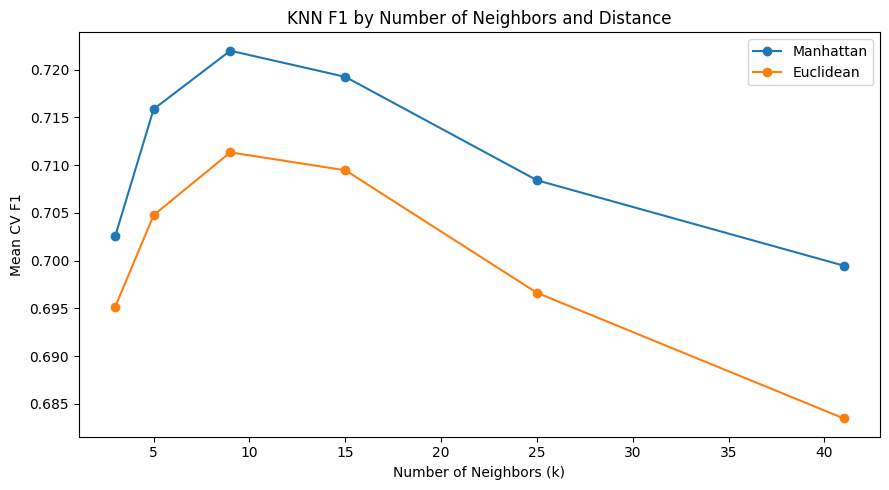

In [ ]:
plt.figure(figsize=(9,5))
for p,label in [(1,'Manhattan'),(2,'Euclidean')]:
    subset = knn_results[(knn_results['param_knn__p']==p)&(knn_results['param_knn__weights']=='uniform')].sort_values('k')
    plt.plot(subset['k'],subset['mean_test_score'],marker='o',label=label)
plt.xlabel('Number of Neighbors (k)');plt.ylabel('Mean CV F1');plt.title('KNN F1 by Number of Neighbors and Distance');plt.legend();plt.tight_layout();plt.show()

The best model used 15 neighbors, Manhattan distance, and distance weighting, with a cross-validation F1 score of 0.7293. I expected the distance metric to affect performance because KNN relies on how similar borrowers are to one another. Manhattan distance performed best in the selected combination, suggesting that the way distances are calculated matters for this dataset.

Distance weighting also produced perfect training accuracy, which suggests that the model memorized the training observations. However, test accuracy was lower at 0.8951. This difference shows that the model did not generalize perfectly, even though cross-validation helped me select the parameters without relying on the test data.

## Tuned KNN and Confusion Matrix

I evaluated the selected model once on the held-out test set. The confusion matrix shows how many actual defaults were identified and how many were missed.

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Week 8 Tuned KNN,1.0,0.8951,0.8721,0.6044,0.7139,0.8829


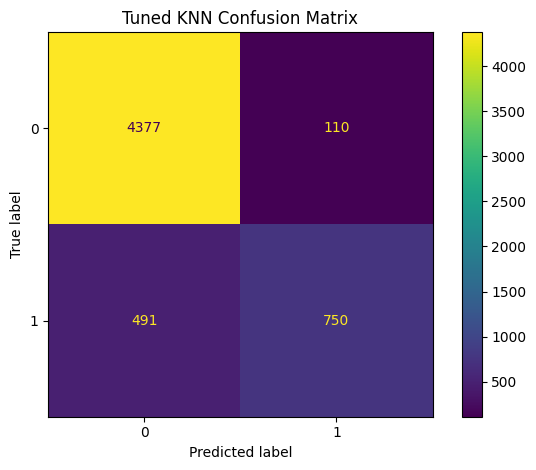

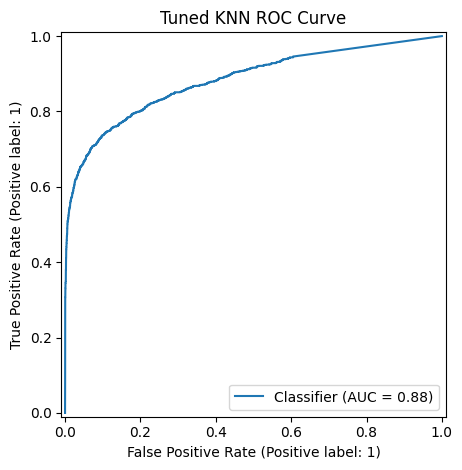

In [ ]:
best_knn = search.best_estimator_
best_pred = best_knn.predict(X_test)
best_prob = best_knn.predict_proba(X_test)[:,1]
knn_summary = pd.DataFrame([{'Model':'Week 8 Tuned KNN','Train Accuracy':best_knn.score(X_train,y_train),'Test Accuracy':accuracy_score(y_test,best_pred),'Precision':precision_score(y_test,best_pred),'Recall':recall_score(y_test,best_pred),'F1 Score':f1_score(y_test,best_pred),'ROC-AUC':roc_auc_score(y_test,best_prob)}])
display(knn_summary.round(4))
ConfusionMatrixDisplay.from_predictions(y_test,best_pred);plt.title('Tuned KNN Confusion Matrix');plt.tight_layout();plt.show()
RocCurveDisplay.from_predictions(y_test,best_prob);plt.title('Tuned KNN ROC Curve');plt.tight_layout();plt.show()

## Model Comparison and Conclusions

The tuned KNN model achieved 0.8951 accuracy, 0.6044 recall, 0.7139 F1, and 0.8829 ROC-AUC. This was an improvement over the baseline KNN model, which had an F1 score of 0.6958 and ROC-AUC of 0.8543. Hyperparameter tuning improved performance, but the improvement was relatively small.

Compared with the Week 6 random forest, KNN performed worse. The random forest achieved an F1 score of 0.8093 and recall of 0.7010, while KNN reached 0.7139 and 0.6044. This suggests that the tree-based model was better at identifying defaults while maintaining a balance between precision and recall.

One result I did not expect was the perfect training accuracy with distance weighting. Although the model performed reasonably well on the test data, the difference between training and testing performance suggests that KNN may be sensitive to individual observations. Overall, KNN provided a useful comparison, but it did not outperform the random forest for predicting loan default.

In [ ]:
print('Week 8 KNN F1:',round(knn_summary.loc[0,'F1 Score'],4))
print('Week 6 random forest F1: 0.8093')
print('KNN minus random forest F1:',round(knn_summary.loc[0,'F1 Score']-0.8093,4))
print('Week 8 KNN recall:',round(knn_summary.loc[0,'Recall'],4))
print('Week 6 random forest recall: 0.7010')

Week 8 KNN F1: 0.7139
Week 6 random forest F1: 0.8093
KNN minus random forest F1: -0.0954
Week 8 KNN recall: 0.6044
Week 6 random forest recall: 0.7010
